## Planning:
- Load data
- Check variable and target
- Check correlation between numeric variable
- Check output to variable impact (using KDE distribution)

In [1]:
import pandas as pd
import numpy as np

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
submit = pd.read_csv("sample_submission.csv")

In [3]:
train.head(3)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0


In [4]:
test.head(3)

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,699960,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,...,Visa,OTP,Online,iPhone,False,False,False,False,False,False
1,699961,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,...,RuPay,PIN,Contactless,Android Phone,False,False,False,False,False,False
2,699962,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,...,Visa,No Authentication,Online,iPhone,False,False,False,False,False,False


In [5]:
train.shape

(699960, 26)

In [8]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-nul

In [6]:
test.shape

(299984, 25)

In [9]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299984 entries, 0 to 299983
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            299984 non-null  int64  
 1   amount_usd                    299984 non-null  float64
 2   hours_since_last_txn          299984 non-null  float64
 3   txn_count_last_24h            299984 non-null  int64  
 4   distance_from_home_km         299984 non-null  float64
 5   card_age_months               299984 non-null  int64  
 6   customer_age                  299984 non-null  int64  
 7   account_balance_usd           299984 non-null  float64
 8   cvv_retry_count               299984 non-null  int64  
 9   velocity_score                299984 non-null  float64
 10  time_of_day_hour              299984 non-null  int64  
 11  day_of_week                   299984 non-null  int64  
 12  merchant_risk_score           299984 non-nul

In [10]:
submit.head(3)

,id,is_fraud
0,699960,0.0167
1,699961,0.0167
2,699962,0.0167


In [11]:
train.groupby('is_fraud')['id'].count()

is_fraud
0.0    688271
1.0     11689
Name: id, dtype: int64

In [12]:
# proportion of each class
train['is_fraud'].value_counts(normalize=True)

is_fraud
0.0    0.9833
1.0    0.0167
Name: proportion, dtype: float64

In [13]:
# very imbalance

In [14]:
# missing data
# calculate percentage missing value in training data
train_missing = pd.DataFrame(train.isna().sum()).reset_index()

In [15]:
train_missing

,index,0
0,id,0
1,amount_usd,0
2,hours_since_last_txn,0
3,txn_count_last_24h,0
4,distance_from_home_km,0
5,card_age_months,0
6,customer_age,0
7,account_balance_usd,0
8,cvv_retry_count,0
9,velocity_score,0


In [16]:
test_missing = pd.DataFrame(test.isna().sum()).reset_index()

In [17]:
test_missing

,index,0
0,id,0
1,amount_usd,0
2,hours_since_last_txn,0
3,txn_count_last_24h,0
4,distance_from_home_km,0
5,card_age_months,0
6,customer_age,0
7,account_balance_usd,0
8,cvv_retry_count,0
9,velocity_score,0


In [18]:
# no missing data. good

In [3]:
# check correlation of numeric variable
# take all column numeric column
numeric_cols = train.drop(columns='id').select_dtypes(include='number').columns.tolist()

In [54]:
numeric_cols

['amount_usd',
 'hours_since_last_txn',
 'txn_count_last_24h',
 'distance_from_home_km',
 'card_age_months',
 'customer_age',
 'account_balance_usd',
 'cvv_retry_count',
 'velocity_score',
 'time_of_day_hour',
 'day_of_week',
 'merchant_risk_score',
 'prior_disputes',
 'is_fraud']

In [4]:
numeric_cols_ex = numeric_cols.copy()

In [5]:
numeric_cols_ex.remove("is_fraud")

In [57]:
numeric_cols_ex

['amount_usd',
 'hours_since_last_txn',
 'txn_count_last_24h',
 'distance_from_home_km',
 'card_age_months',
 'customer_age',
 'account_balance_usd',
 'cvv_retry_count',
 'velocity_score',
 'time_of_day_hour',
 'day_of_week',
 'merchant_risk_score',
 'prior_disputes']

In [25]:
len(numeric_cols)

14

In [6]:
bool_cols = train.select_dtypes(include='bool').columns.tolist()

In [7]:
bool_cols

['is_foreign_transaction',
 'is_new_merchant',
 'used_vpn',
 'ip_country_mismatch',
 'billing_shipping_mismatch',
 'is_ai_generated_scam_attempt']

In [26]:
len(bool_cols)

6

In [8]:
obj_cols = train.select_dtypes(include='object').columns.tolist()

In [24]:
obj_cols

['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']

In [67]:
train[obj_cols].head(5)

,merchant_category,card_type,auth_method,channel,device_type
0,Groceries,Mastercard,OTP,POS,iPhone
1,Online Retail,Visa,PIN,In-App,Android Phone
2,Utilities,Visa,OTP,Online,Tablet
3,Groceries,Mastercard,3D Secure,POS,Android Phone
4,Electronics,Visa,3D Secure,Online,Windows PC


In [27]:
len(obj_cols)

5

In [28]:
matrix_corr = train[numeric_cols].corr()

In [29]:
# correlation
import seaborn as sns
import matplotlib.pyplot as plt

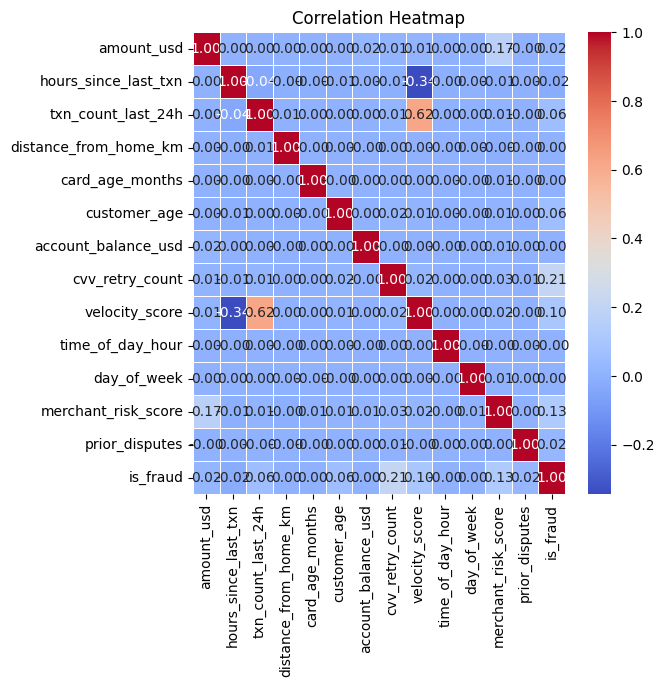

In [31]:
plt.figure(figsize=(6,6))
sns.heatmap(matrix_corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

In [32]:
# lets check the connection between target and input

In [40]:
PALETTE = {1: "#4C72B0", 0: "#DD8452"}  

# 4C72B0 = Blue
# DD8452 = Orange

In [38]:
sample_df = train.sample(n=10000, random_state=42)

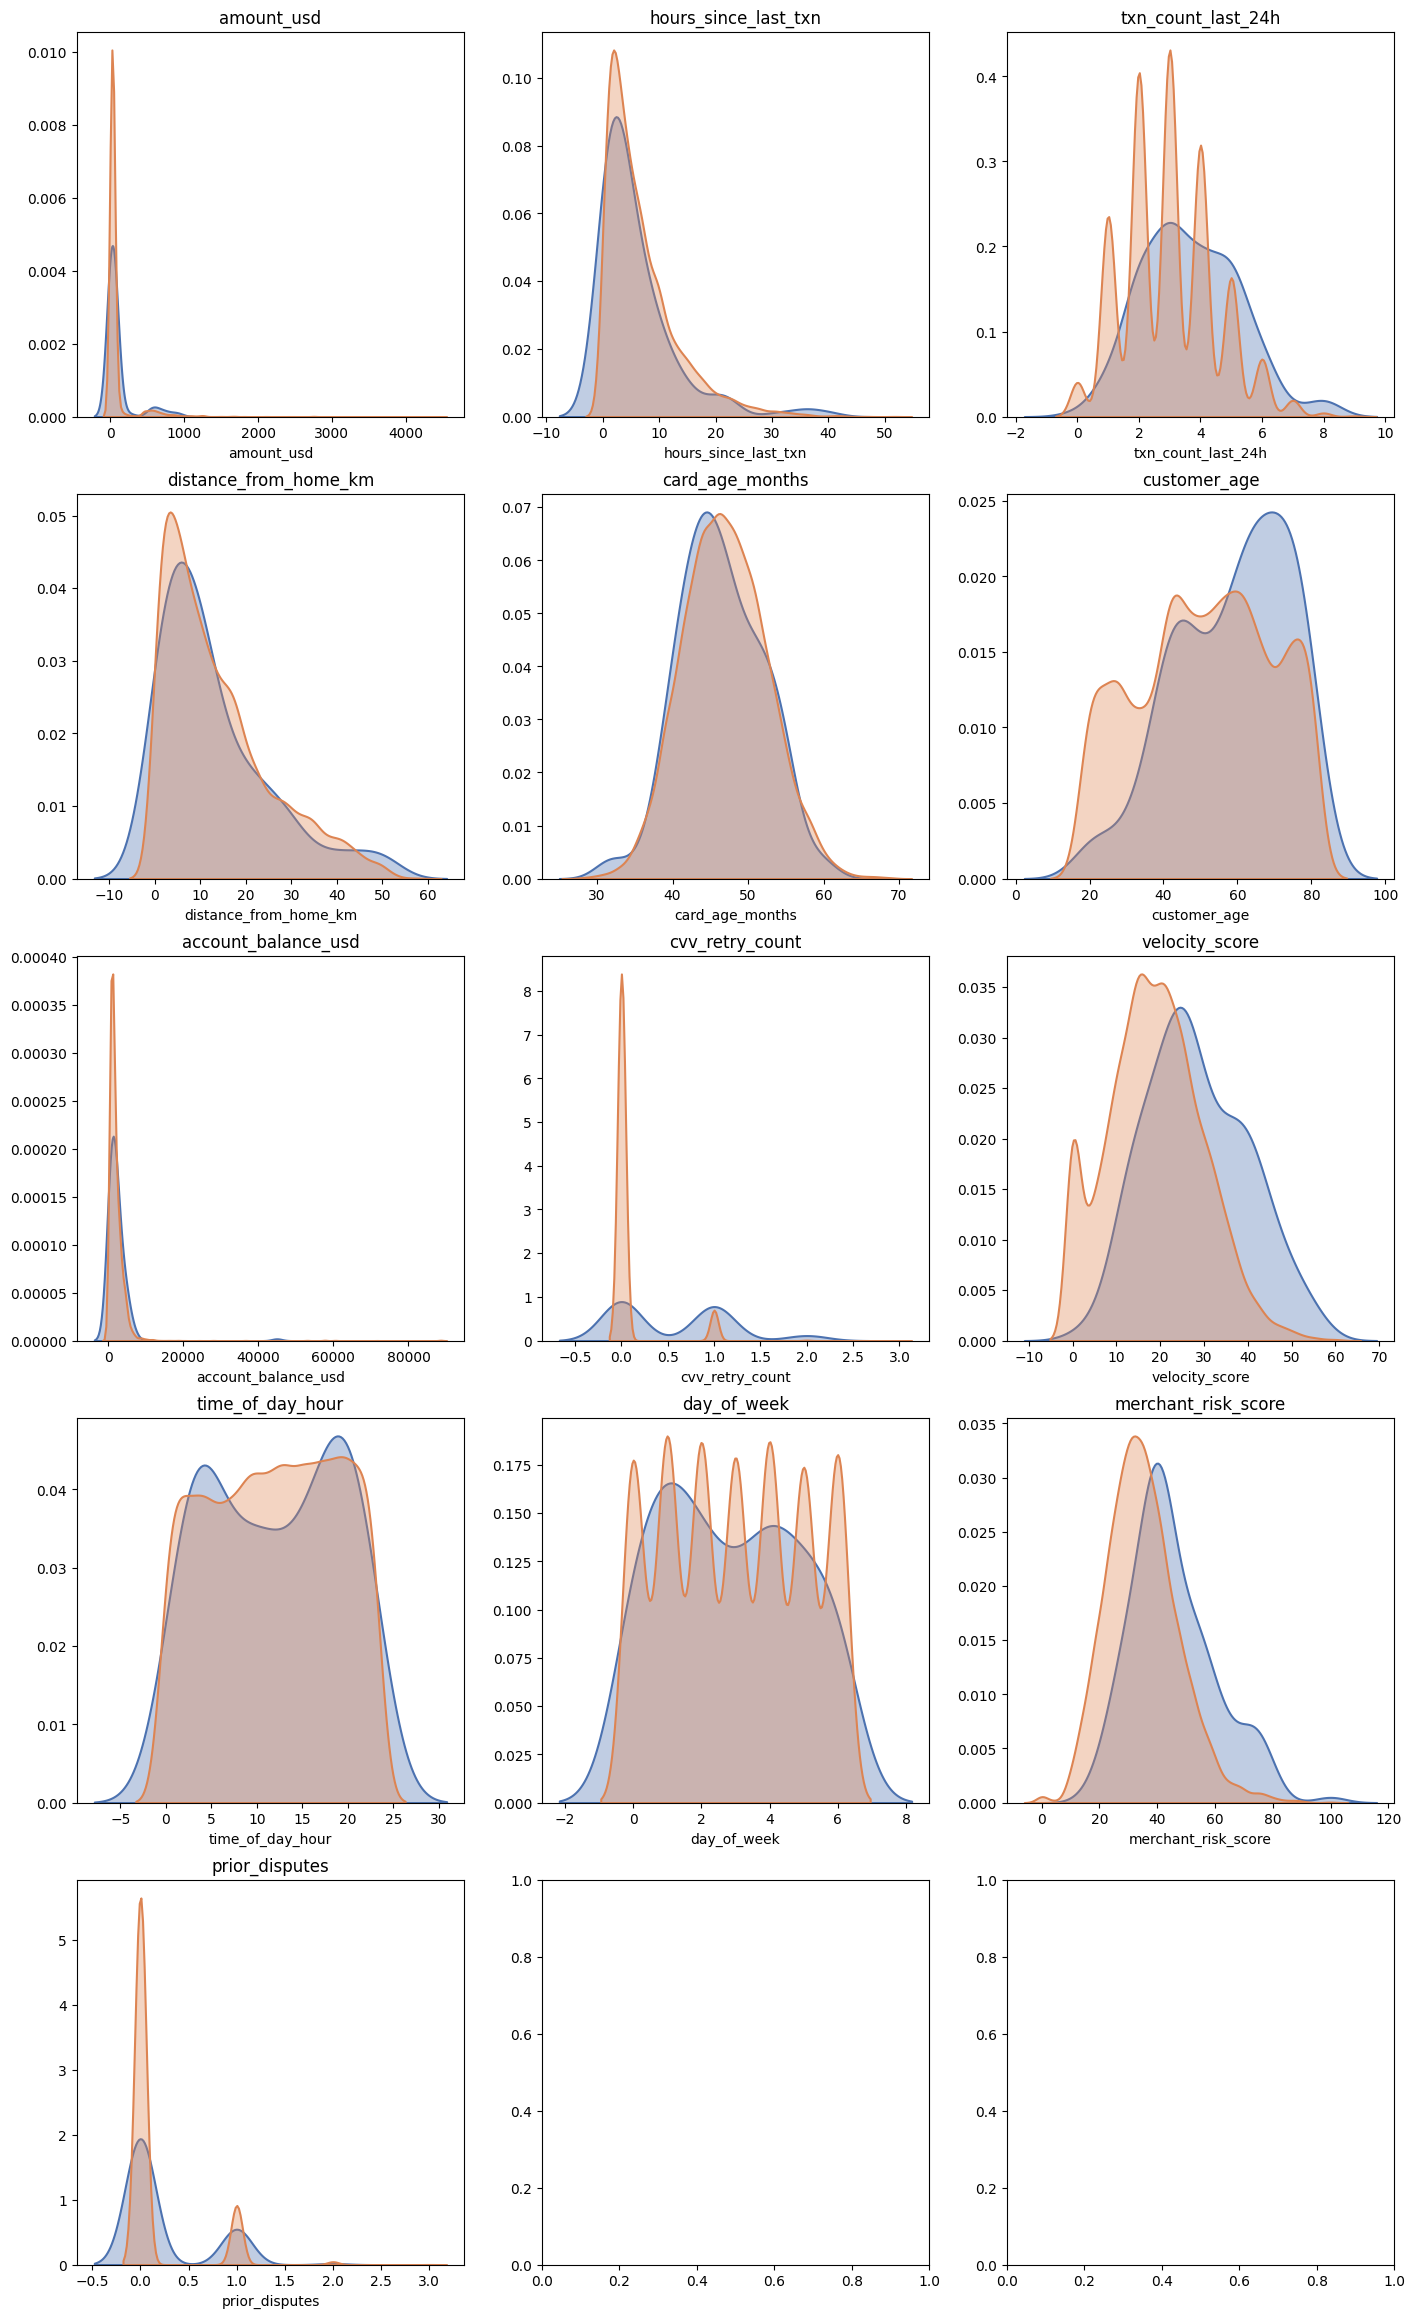

In [60]:
fig, axes = plt.subplots(5, 3, figsize=(17, 29))

for ax, col in zip(axes.flatten(), numeric_cols_ex):
    for label, color in PALETTE.items():
        sns.kdeplot(sample_df.drop(columns=["id"]).loc[sample_df["is_fraud"] == label, col].dropna(),
                    ax=ax, 
                    fill=True, 
                    alpha=0.35, 
                    color=color, 
                    linewidth=1.5,
                    label=str(label))
    ax.set_title(col)
    ax.set_ylabel("")

## Basic Modeling

For logistic regression, create dummy variable

In [9]:
train_dummy = pd.get_dummies(train, columns= obj_cols,drop_first=True, dtype=int)
test_dummy = pd.get_dummies(test, columns = obj_cols,drop_first=True, dtype=int)

## Logistic Regression

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

In [12]:
X = train_dummy.drop(columns=["id","is_fraud"])
y = train_dummy["is_fraud"]
X_test = test_dummy.drop(columns=["id"])

In [63]:
def fit_logit(X_tr, y_tr, X_va, y_va):
    model = LogisticRegression()
    model.fit(X_tr, y_tr)
    return (model.predict_proba(X_va)[:, 1],
            model.predict_proba(X_test)[:, 1])

In [64]:
# 2. Initialize the Logistic Regression model
model = LogisticRegression(random_state=42)

# 3. Set up 5-Fold Cross-Validation
# StratifiedKFold ensures each fold has the same percentage of samples for each class
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [65]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [70]:
# Create a pipeline that scales the data before fitting Logistic Regression
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))

# Then use it in your cross-validation
auc_scores = cross_val_score(estimator=model, X=X, y=y, cv=cv, scoring='roc_auc')

In [71]:
# 5. Output the results
print("AUC-ROC scores for each fold:")
for i, score in enumerate(auc_scores, 1):
    print(f"  Fold {i}: {score:.4f}")

print(f"\nMean AUC-ROC Score: {np.mean(auc_scores):.4f}")
print(f"Standard Deviation: {np.std(auc_scores):.4f}")

AUC-ROC scores for each fold:
  Fold 1: 0.9410
  Fold 2: 0.9435
  Fold 3: 0.9465
  Fold 4: 0.9415
  Fold 5: 0.9361

Mean AUC-ROC Score: 0.9417
Standard Deviation: 0.0034


In [72]:
model.fit(X,y)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [73]:
# 1. Generate predicted class labels (True/False or 0/1) for the test set
test_predictions = model.predict(X_test)

In [75]:
test_probabilities = model.predict_proba(X_test)[:, 1]

In [76]:
submit['is_fraud'] = test_probabilities
submit.to_csv('sub_logit_1.csv', index=False)

In [77]:
# create OOF
train_probabilities = model.predict_proba(X)[:, 1]

In [78]:
name = "log_5cv"

In [81]:
oof_df = train[['id']].copy()
oof_df.loc[:,name] = train_probabilities
oof_df.to_csv(f'oof_{name}.csv',index=False)